# Hyper Sweep

In [1]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import polars.selectors as cs

from datetime import date
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator, EngFormatter
from privacy_and_grokking.artifacts.local import get_plots_dir
from shared import setup, SETUPS, preprocess_info_rmia, preprocess_metrics_df

In [2]:
setup()

In [3]:
# info_rmia_df = pl.read_parquet("../../cache/canary-selection-v1/informia_results.parquet")
# info_rmia_df = preprocess_info_rmia(info_rmia_df)

metrics_df = pl.read_parquet("../../cache/hyper-sweep-v2_mlflow_export.parquet")
metrics_df = preprocess_metrics_df(metrics_df, cols=["params.weight_decay", "params.initialization_scale", "params.train_size"])

## Overview

In [4]:
metrics_df.head()

run_id,run_name,step,timestamp,params.weight_decay,params.initialization_scale,params.train_size,epoch,eval/generalization_gap,eval/train/accuracy,eval/train/canary_accuracy,eval/train/loss/cross_entropy/mean,eval/train/loss/cross_entropy/std,eval/train/loss/mse/mean,eval/train/loss/mse/std,eval/train/canary_loss/cross_entropy/mean,eval/train/canary_loss/cross_entropy/std,eval/train/canary_loss/mse/mean,eval/train/canary_loss/mse/std,eval/loss/canary_mse/overlap,eval/loss/ce/overlap,eval/loss/mse/overlap,eval/loss/canary_ce/overlap,eval/loss/train_plus_canary_vs_test/mse/overlap,eval/loss/train_plus_canary_vs_test/ce/overlap,eval/loss/train_canary_vs_test/ce/overlap,eval/loss/train_canary_vs_test/mse/overlap,eval/nc/nc3,eval/nc/nc4,eval/nc/nc4_test,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_equinorm,eval/nc/nc2_equinorm_weights,eval/nc/nc1,…,eval/grad_norm/attn.in_proj_weight,eval/grad_norm/pos_embed,eval/grad_norm/attn.out_proj.bias,eval/grad_norm/attn.in_proj_bias,eval/grad_norm/token_embed.weight,eval/grad_norm/mlp.2.weight,eval/grad_norm/mlp.0.weight,eval/grad_norm/mlp.2.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/grad_norm/vit.conv_proj.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/grad_norm/vit.conv_proj.weight,eval/grad_norm/vit.class_token,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/grad_norm/vit.encoder.pos_embedding,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/grad_norm/vit.heads.head.weight,eval/grad_norm/vit.heads.head.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/weight_norm/vit.heads.head.bias,eval/weight_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/weight_norm/vit.encoder.pos_embedding,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/weight_norm/vit.conv_proj.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/weight_norm/vit.heads.head.weight,eval/weight_norm/vit.class_token,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,title
str,str,i64,datetime[ms],str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""0098e4d3c6594c2fa17813d190d8a5…","""16.0_0.001_2000_GROK_MNIST_MSE…",0,2026-09-07 04:26:15.569,"""0.001""","""16.0""","""1000""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""(I) MLP (MSE) Grokking"""
"""0098e4d3c6594c2fa17813d190d8a5…","""16.0_0.001_2000_GROK_MNIST_MSE…",0,2026-09-07 04:24:24.682,"""0.001""","""16.0""","""1000""",null,-0.006553,0.118947,0.1,478.388519,343.636261,96400.257812,156419.296875,511.044647,352.281189,108161.46875,180275.515625,0.69,0.899526,0.933147,0.54,0.9389,0.8987,0.6225,0.7889,1.931628,0.861053,0.86,0.126596,0.210194,0.080215,0.263422,0.24734,0.02990

In [5]:
metrics_df.describe()

statistic,run_id,run_name,step,timestamp,params.weight_decay,params.initialization_scale,params.train_size,epoch,eval/generalization_gap,eval/train/accuracy,eval/train/canary_accuracy,eval/train/loss/cross_entropy/mean,eval/train/loss/cross_entropy/std,eval/train/loss/mse/mean,eval/train/loss/mse/std,eval/train/canary_loss/cross_entropy/mean,eval/train/canary_loss/cross_entropy/std,eval/train/canary_loss/mse/mean,eval/train/canary_loss/mse/std,eval/loss/canary_mse/overlap,eval/loss/ce/overlap,eval/loss/mse/overlap,eval/loss/canary_ce/overlap,eval/loss/train_plus_canary_vs_test/mse/overlap,eval/loss/train_plus_canary_vs_test/ce/overlap,eval/loss/train_canary_vs_test/ce/overlap,eval/loss/train_canary_vs_test/mse/overlap,eval/nc/nc3,eval/nc/nc4,eval/nc/nc4_test,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_equinorm,eval/nc/nc2_equinorm_weights,…,eval/grad_norm/attn.in_proj_weight,eval/grad_norm/pos_embed,eval/grad_norm/attn.out_proj.bias,eval/grad_norm/attn.in_proj_bias,eval/grad_norm/token_embed.weight,eval/grad_norm/mlp.2.weight,eval/grad_norm/mlp.0.weight,eval/grad_norm/mlp.2.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/grad_norm/vit.conv_proj.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/grad_norm/vit.conv_proj.weight,eval/grad_norm/vit.class_token,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/grad_norm/vit.encoder.pos_embedding,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/grad_norm/vit.heads.head.weight,eval/grad_norm/vit.heads.head.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/weight_norm/vit.heads.head.bias,eval/weight_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/weight_norm/vit.encoder.pos_embedding,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/weight_norm/vit.conv_proj.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/weight_norm/vit.heads.head.weight,eval/weight_norm/vit.class_token,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,title
str,str,str,f64,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""count""","""432250""","""432250""",432250.0,"""432250""","""432250""","""432250""","""432250""",157839.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,316450.0,301770.0,303908.0,303908.0,303908.0,303908.0,303908.0,303908.0,302178.0,302721.0,…,65120.0,65120.0,65120.0,65120.0,65120.0,65120.0,65120.0,65120.0,83262.0,83262.0,83262.0,83262.0,83262.0,83262.0,83262.0,83262.0,83262.0,83262.0,83262.0,83262.0,83262.0,83262.0,83670.0,83670.0,83670.0,83670.0,83670.0,83670.0,83670.0,83670.0,83670.0,83670.0,83670.0,83670.0,83670.0,83670.0,"""387530"""
"""null_count""","""0""","""0""",0.0,"""0""","""0""","""0""","""0""",274411.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.0,115800.

In [6]:
metrics_df.columns

['run_id',
 'run_name',
 'step',
 'timestamp',
 'params.weight_decay',
 'params.initialization_scale',
 'params.train_size',
 'epoch',
 'eval/generalization_gap',
 'eval/train/accuracy',
 'eval/train/canary_accuracy',
 'eval/train/loss/cross_entropy/mean',
 'eval/train/loss/cross_entropy/std',
 'eval/train/loss/mse/mean',
 'eval/train/loss/mse/std',
 'eval/train/canary_loss/cross_entropy/mean',
 'eval/train/canary_loss/cross_entropy/std',
 'eval/train/canary_loss/mse/mean',
 'eval/train/canary_loss/mse/std',
 'eval/loss/canary_mse/overlap',
 'eval/loss/ce/overlap',
 'eval/loss/mse/overlap',
 'eval/loss/canary_ce/overlap',
 'eval/loss/train_plus_canary_vs_test/mse/overlap',
 'eval/loss/train_plus_canary_vs_test/ce/overlap',
 'eval/loss/train_canary_vs_test/ce/overlap',
 'eval/loss/train_canary_vs_test/mse/overlap',
 'eval/nc/nc3',
 'eval/nc/nc4',
 'eval/nc/nc4_test',
 'eval/nc/nc2_maximal_angle_equiangularity_weights',
 'eval/nc/nc2_maximal_angle_equiangularity',
 'eval/nc/nc2_equiangul

In [7]:
metrics_df.group_by("title").agg(pl.col("step").max())

title,step
str,i64
null,150000
"""(II) MLP (MSE) No Grokking""",150000
"""(V) ViT (CE) Grokking""",150000
"""(I) MLP (MSE) Grokking""",150000
"""(IV) MLP (CE) No Grokking""",150000
"""(VI) ViT (CE) No Grokking""",150000
"""(VII) MADD (CE) Grokking""",150000
"""(III) MLP (CE) Grokking""",150000


## Analysis

In [8]:
PLOTS = get_plots_dir()

In [9]:
def get_default_value(df: pl.DataFrame, col: str) -> str:
    return df.group_by([col]).len().filter(pl.col("len") == pl.col("len").max())[col][0]

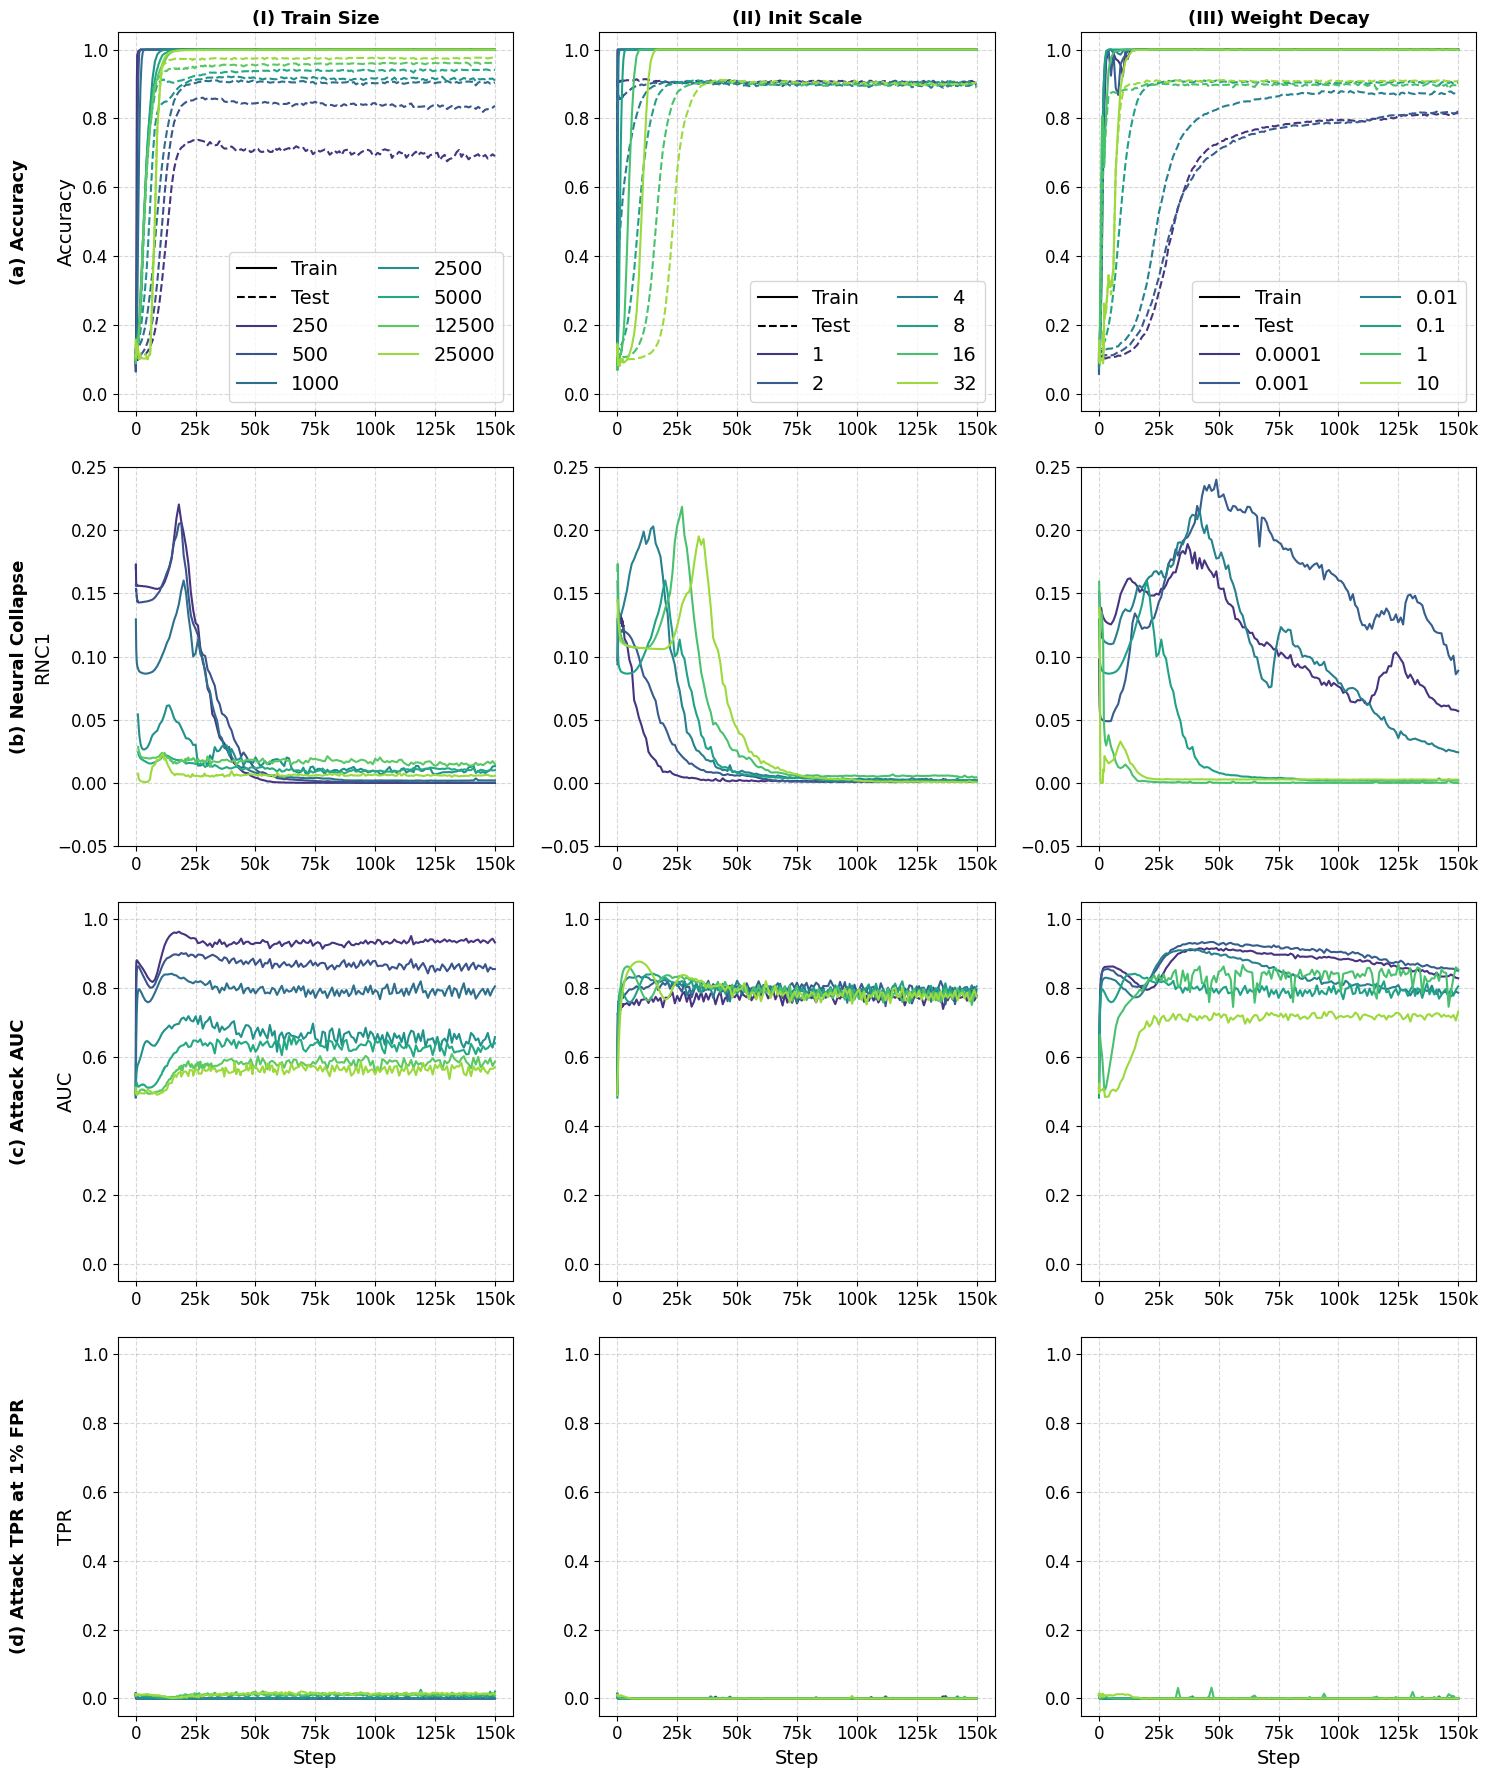

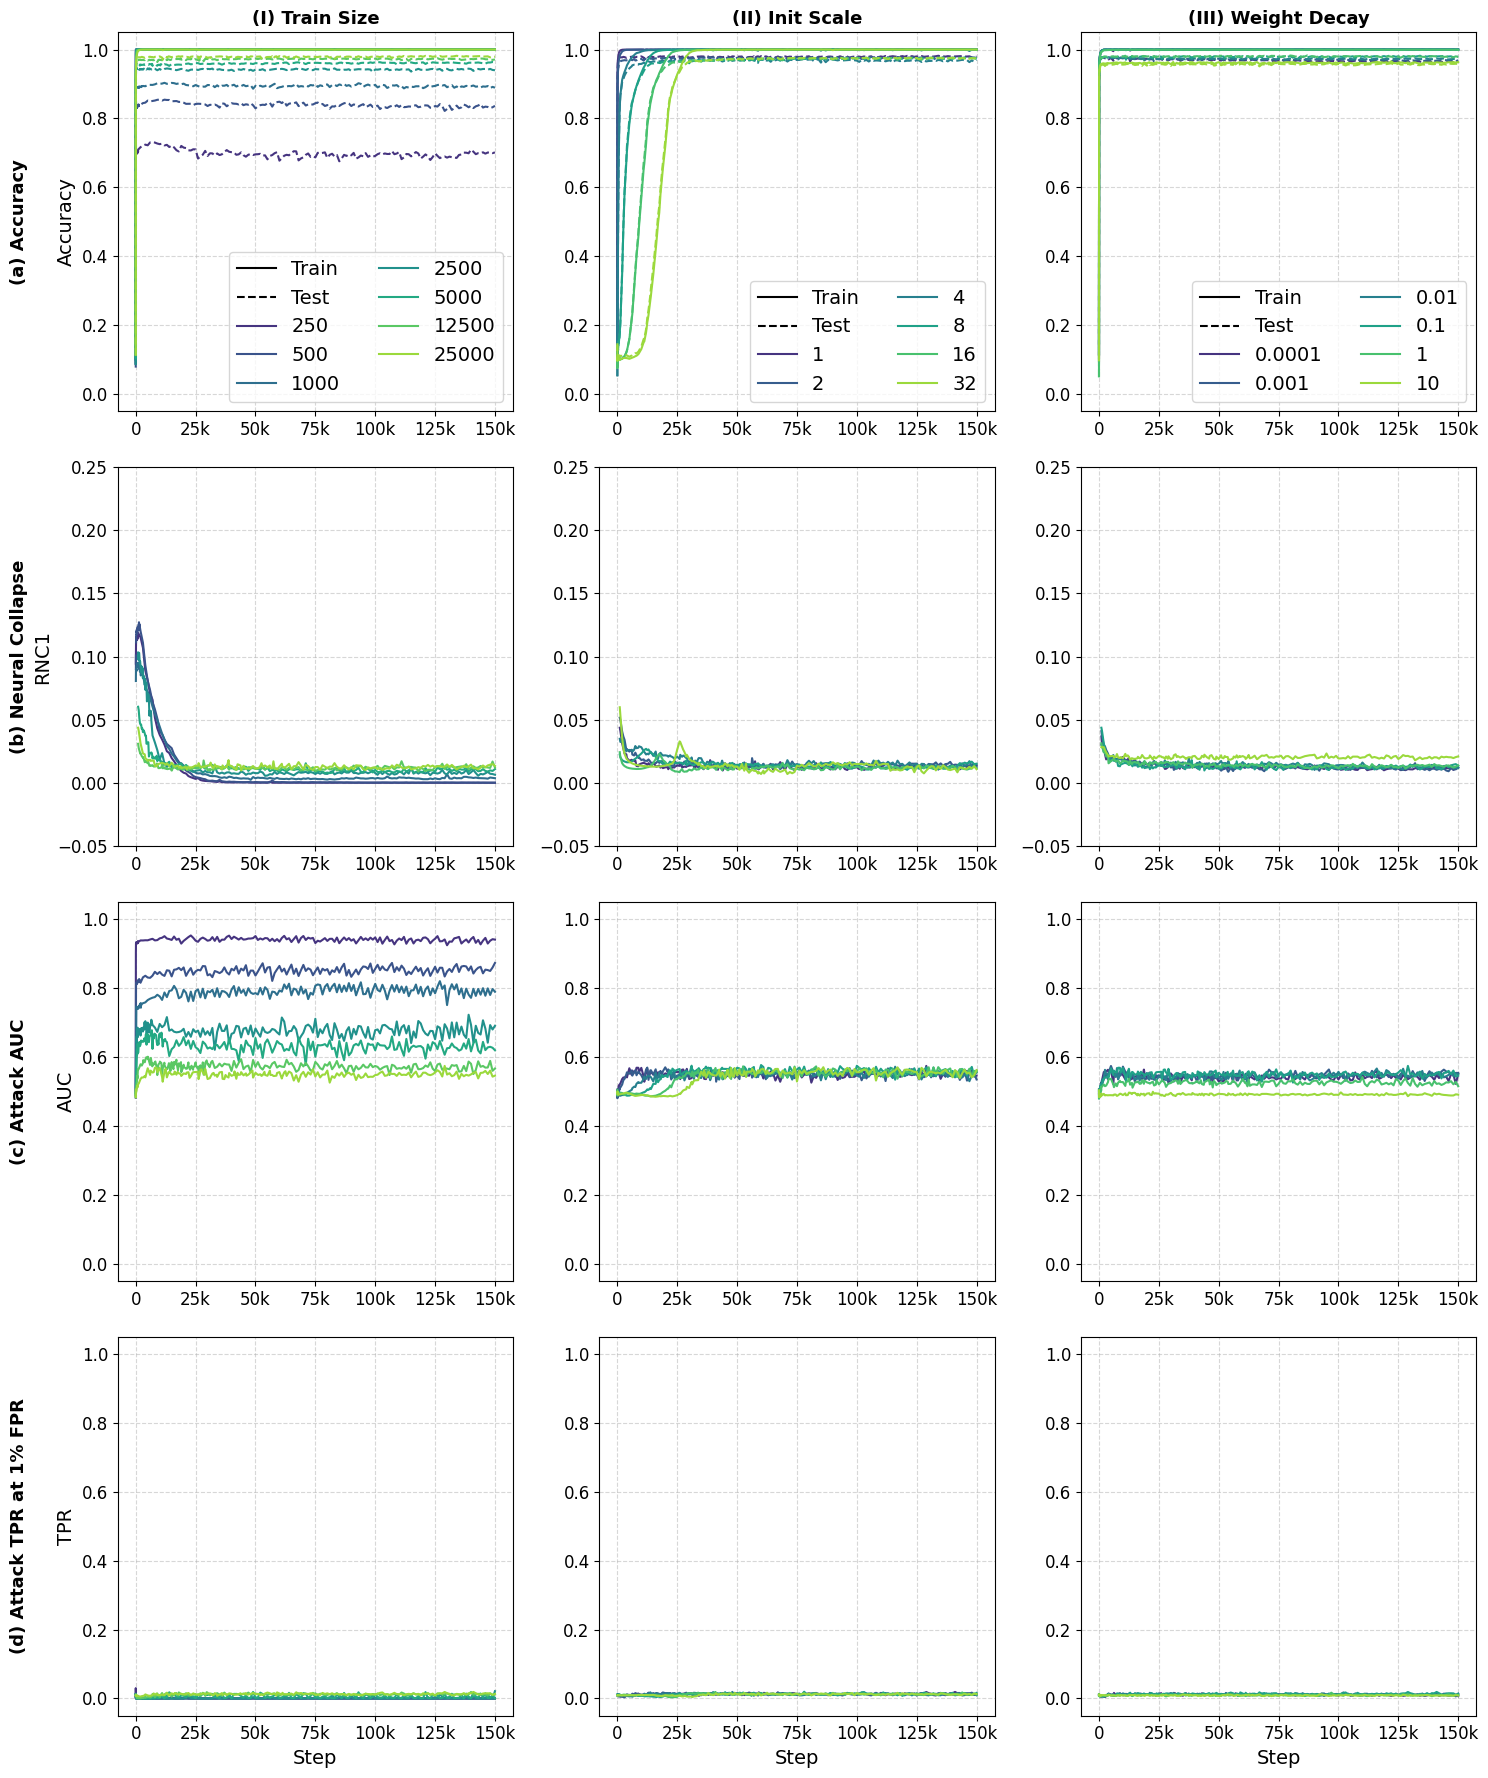

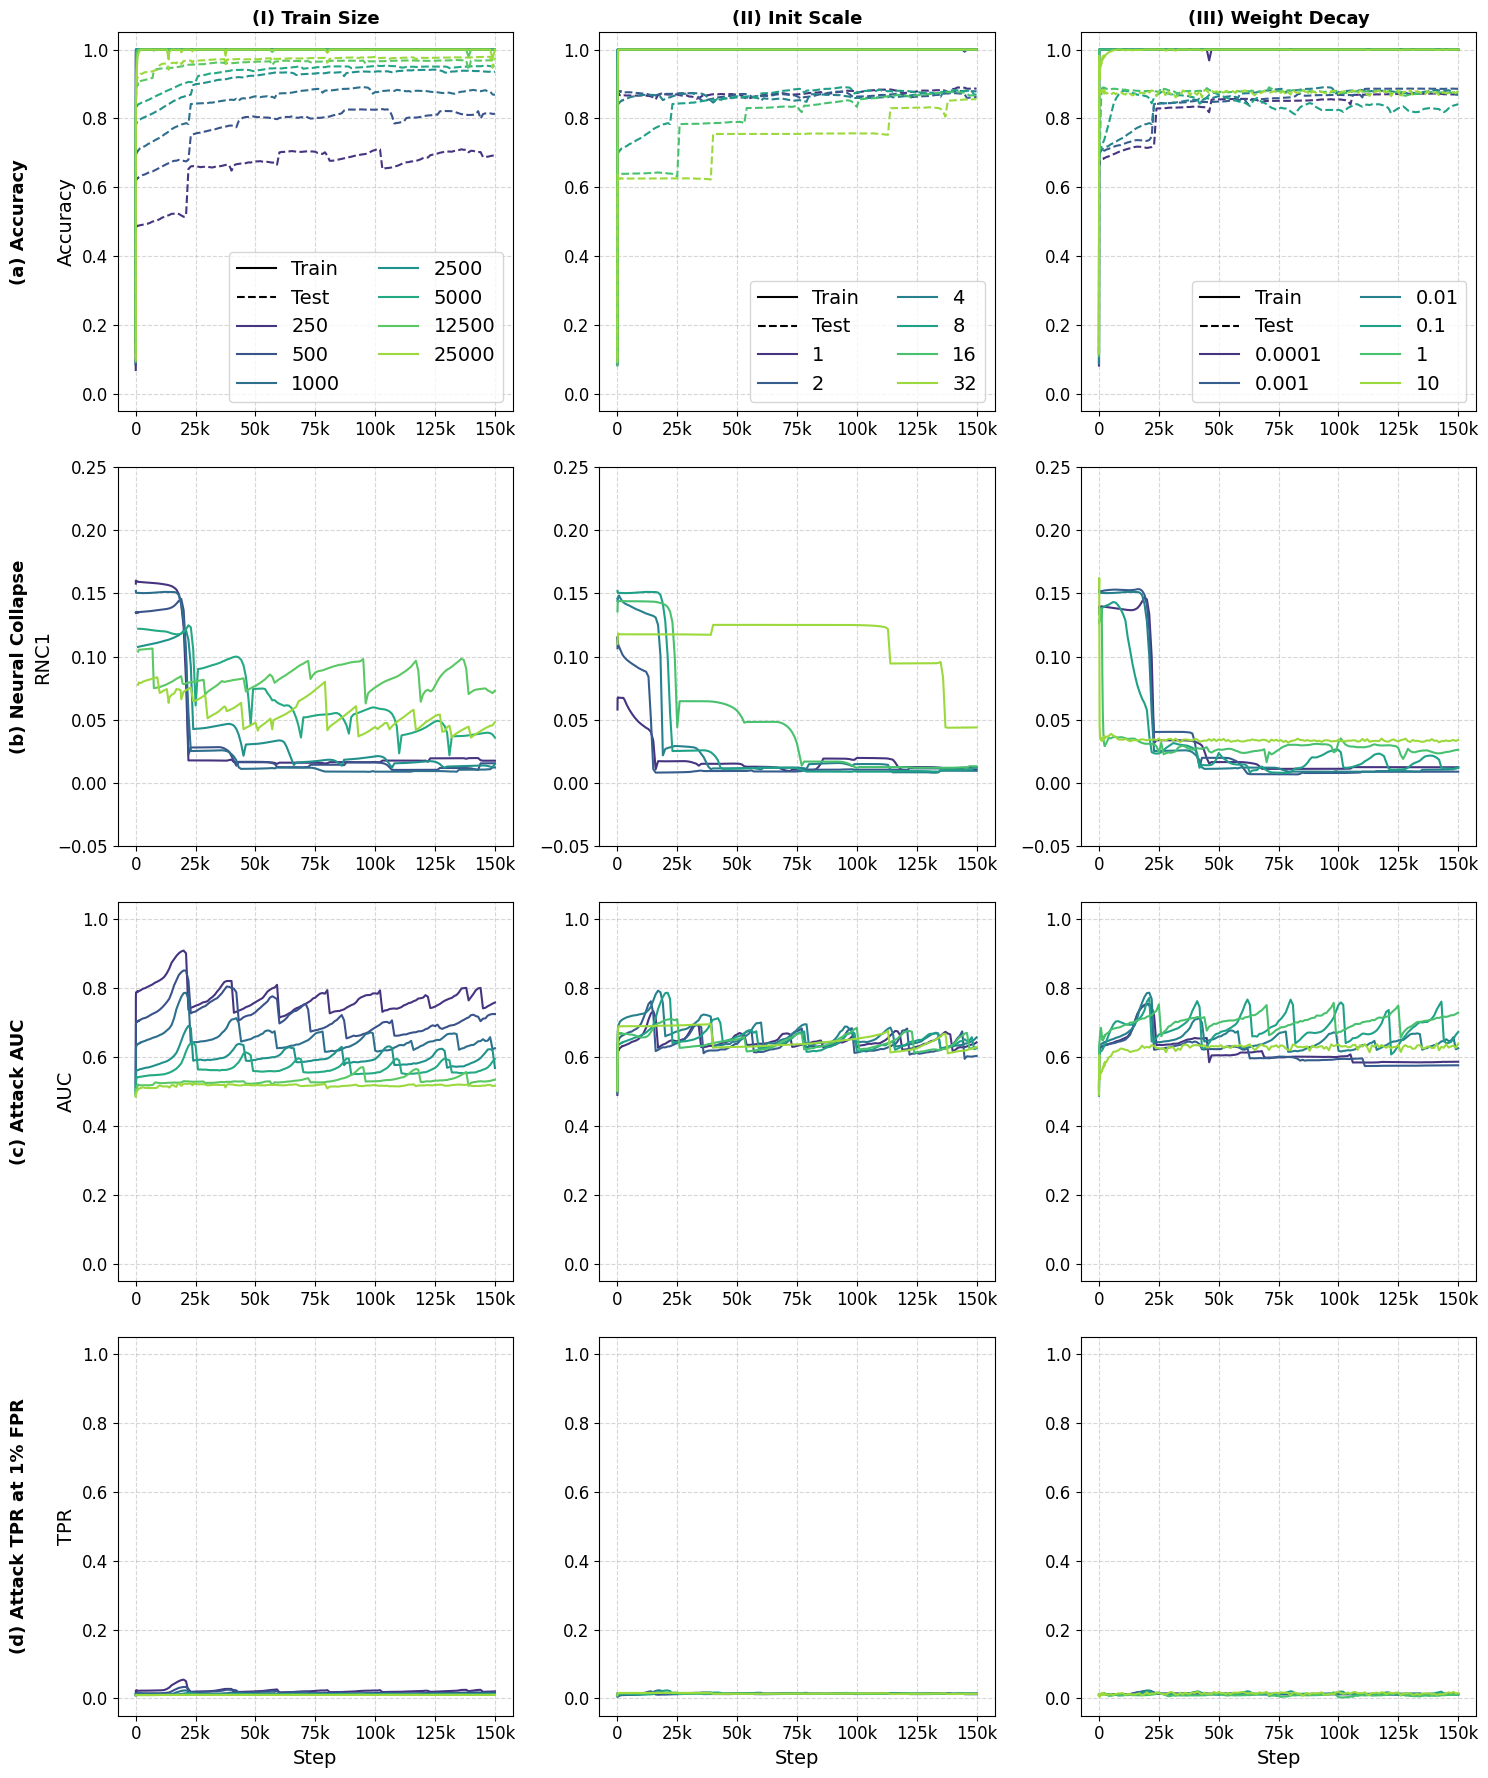

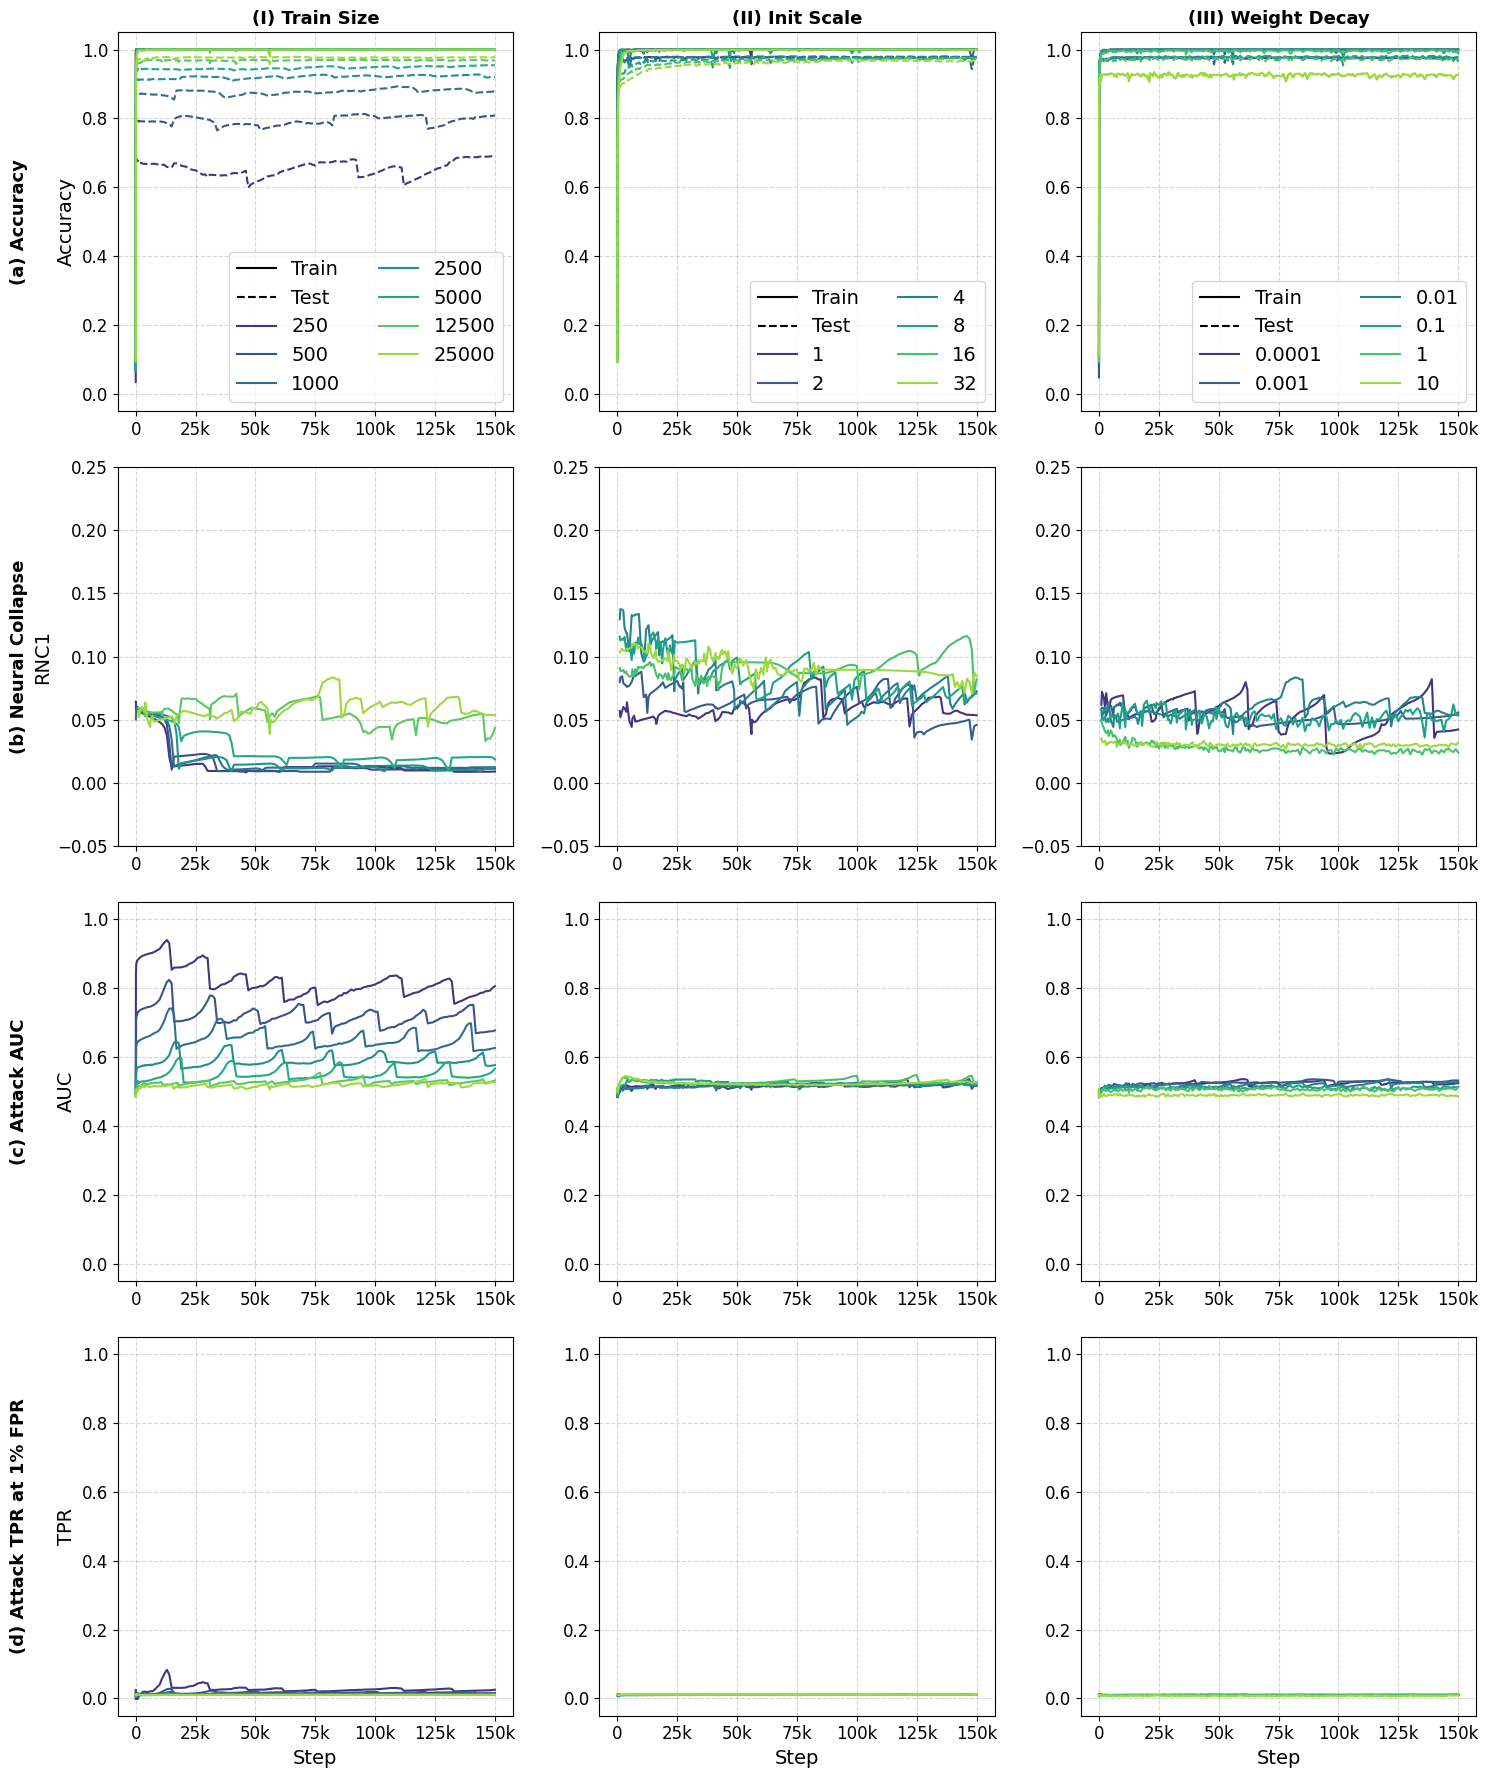

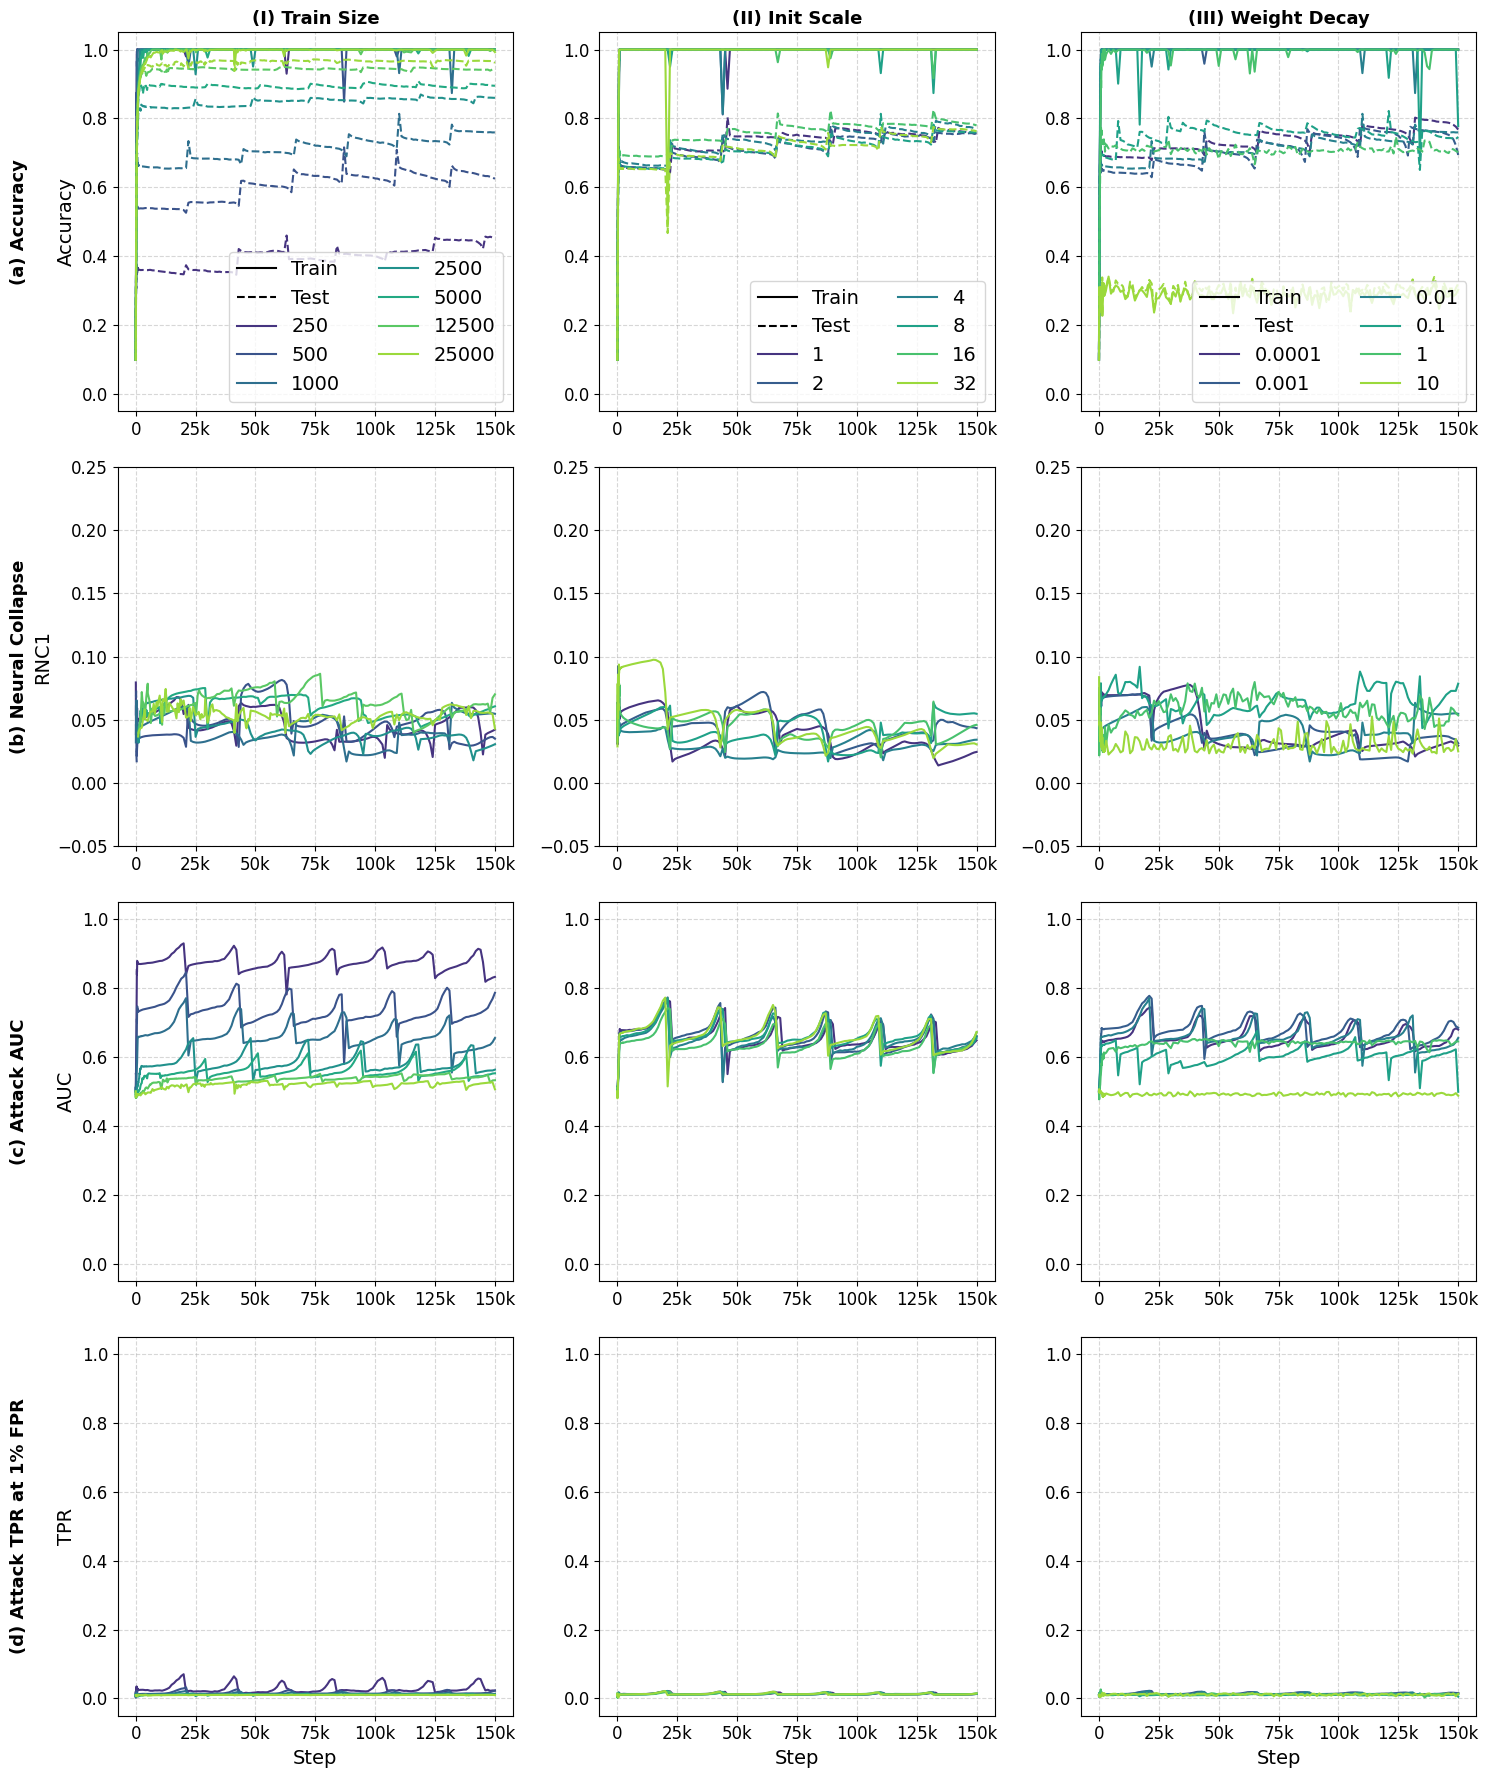

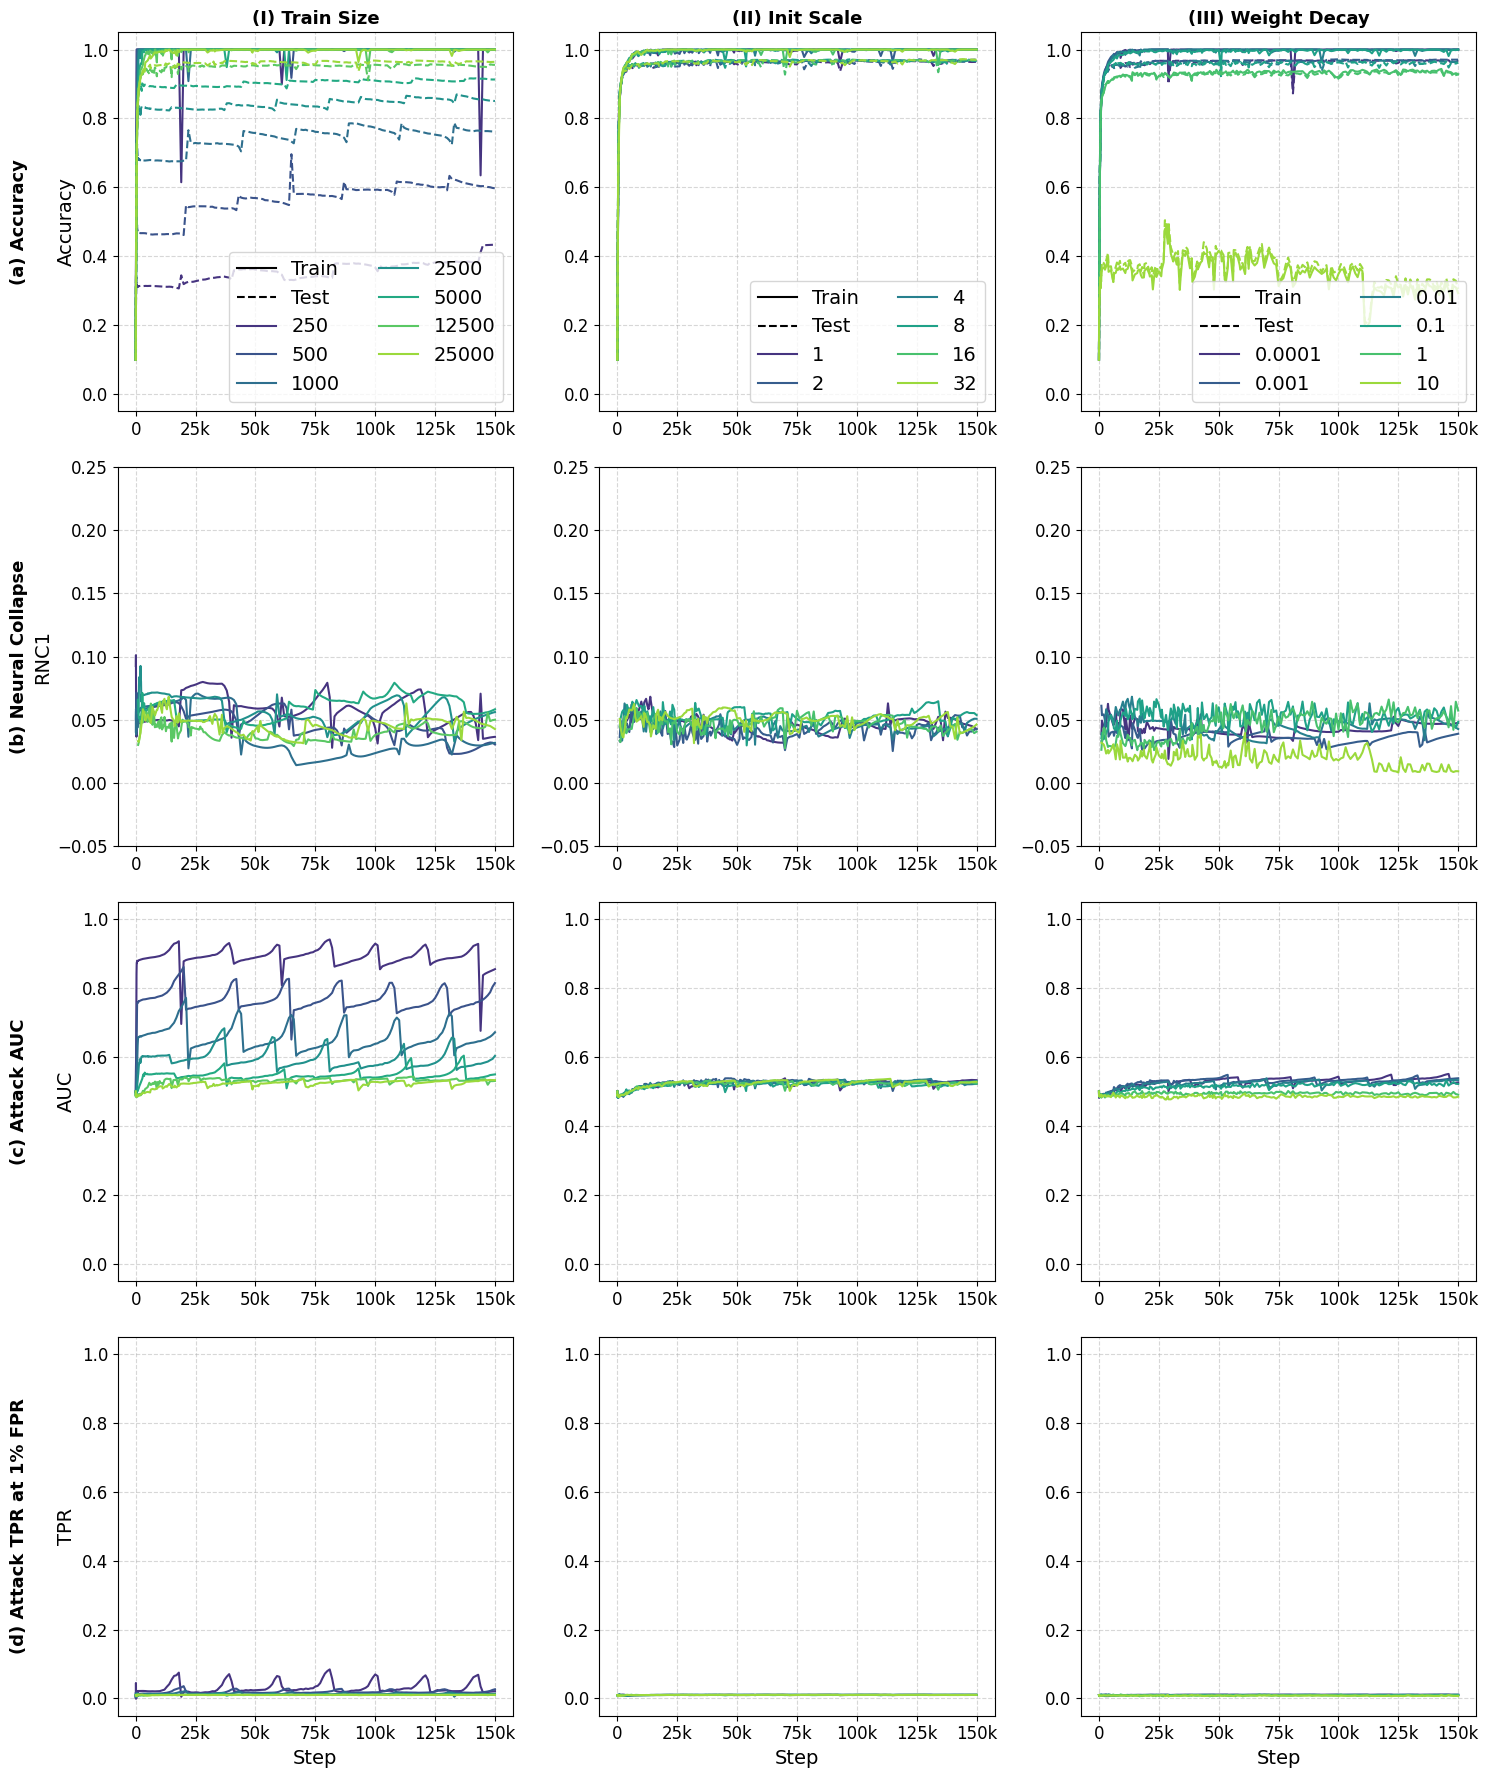

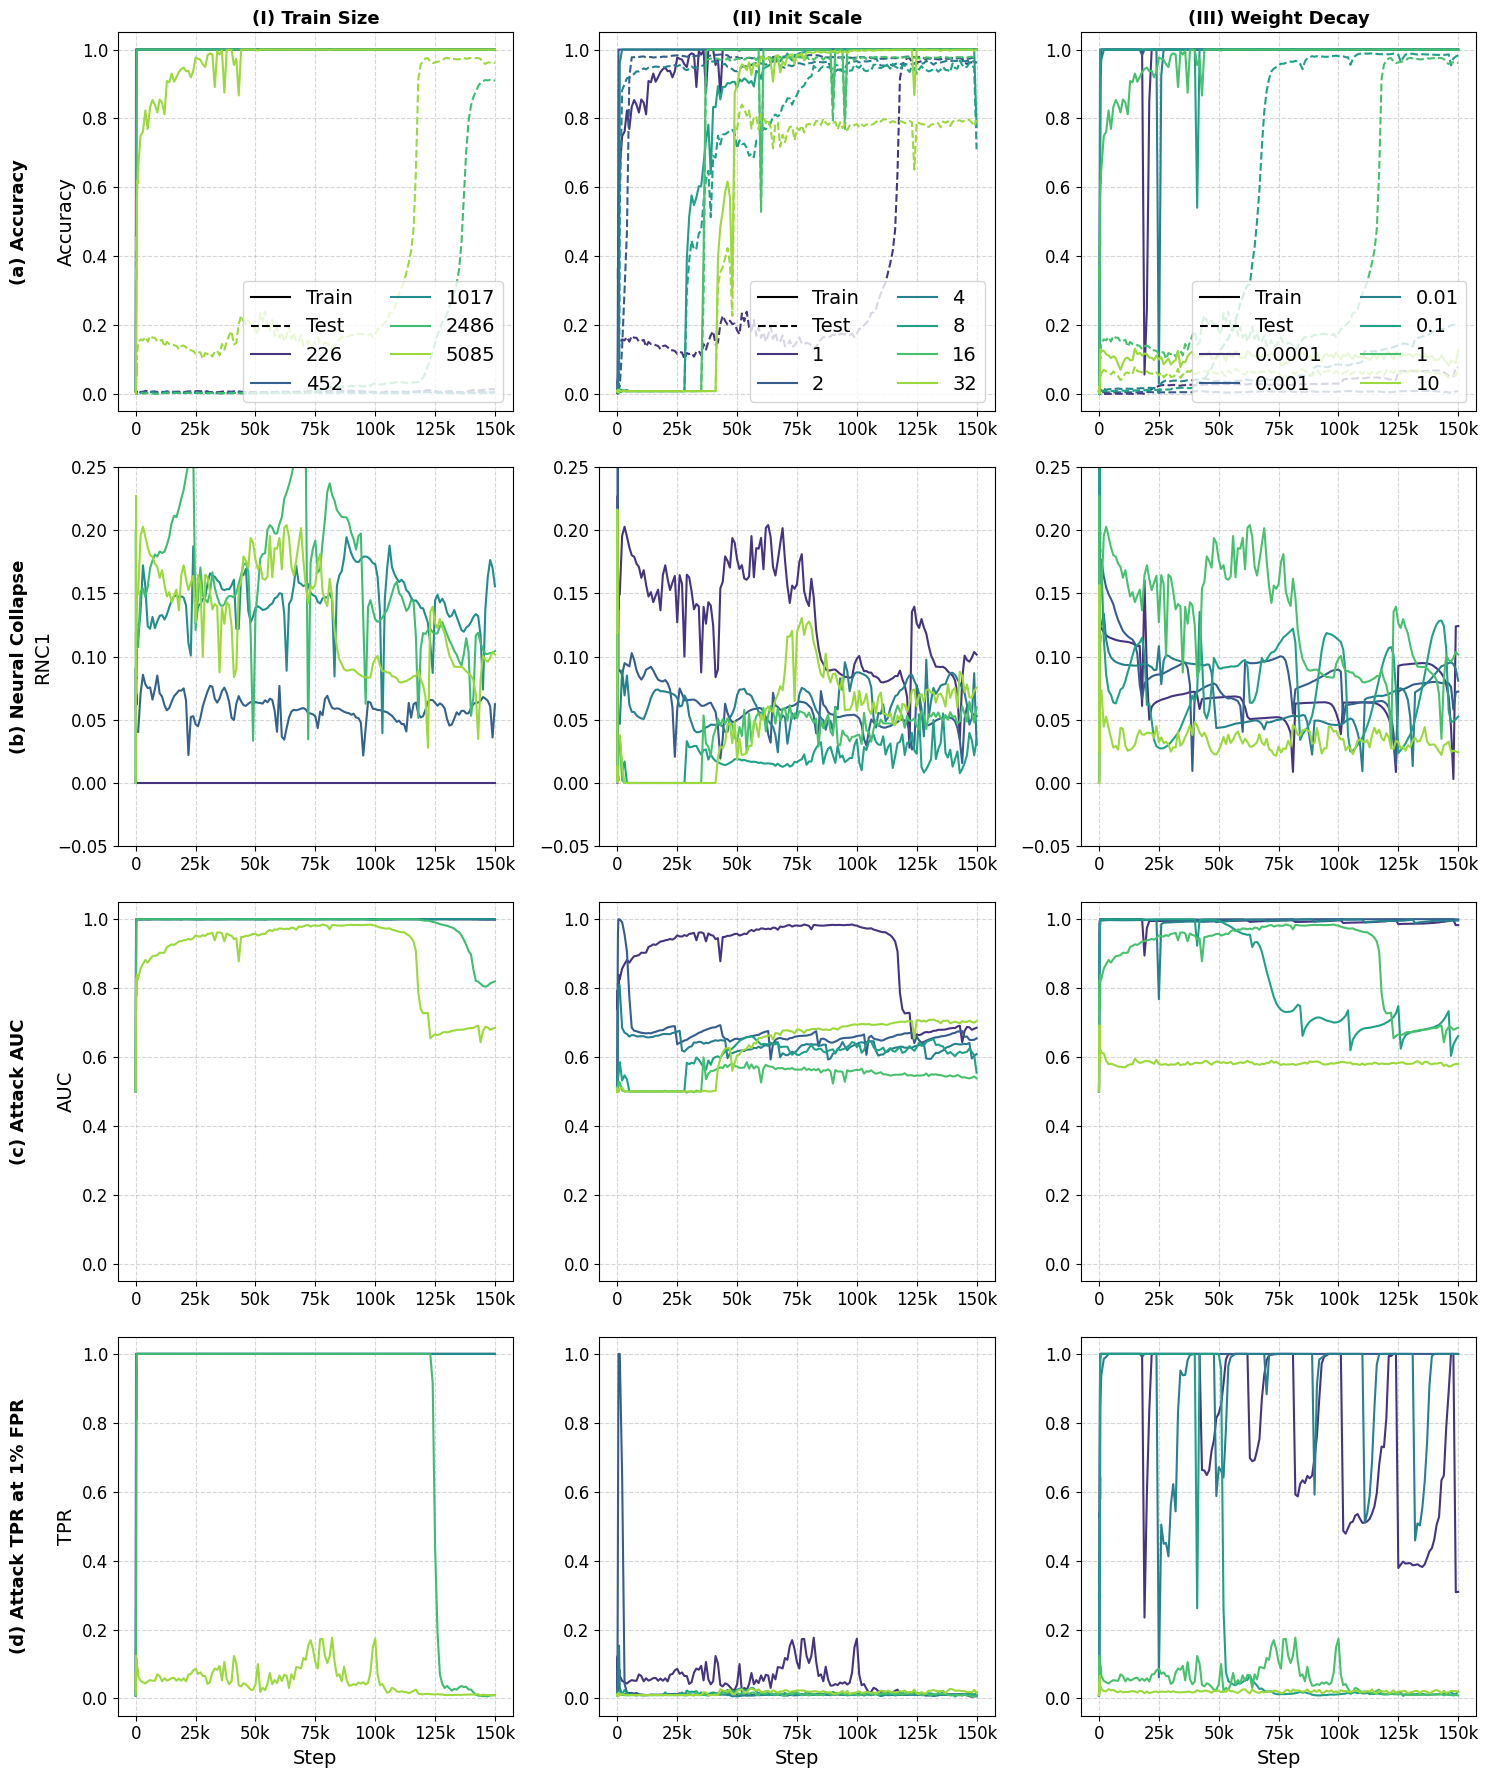

In [10]:
N_COLS = 3
N_ROWS = 4

col_titles = ["(I) Train Size", "(II) Init Scale", "(III) Weight Decay"]
col_variables = ["params.train_size", "params.initialization_scale", "params.weight_decay"]

cmap = cm.viridis

for key, name in SETUPS.items():
    fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5 * N_COLS, 4.5 * N_ROWS))
    axes = axes.T
    filtered_df = metrics_df.filter(pl.col("title") == name)
    loss = "mse_loss" if "mse" in name else "ce_loss"

    default_values = [get_default_value(filtered_df, var) for var in col_variables]

    for col in range(N_COLS):
        ax = axes[col]
        fixed = [(i, col_variables[i]) for i in range(N_COLS) if i != col]
        groups = (
            filtered_df
            .filter((pl.col(var) == default_values[i]) for i, var in fixed)
            .sort(pl.col(col_variables[col]).cast(pl.Float64, strict=False))
            .group_by(col_variables[col], maintain_order=True)
        )

        val_list = [float(k[0] if isinstance(k, tuple) else k) for k, _ in groups]
        min_val, max_val = min(val_list), max(val_list)

        if min_val > 0 and (max_val / min_val) >= 2:
            norm = LogNorm(vmin=min_val, vmax=max_val)
        else:
            norm = Normalize(vmin=min_val, vmax=max_val)

        if min_val == max_val:
            color_map = {v: cmap(0.5) for v in val_list}
        else:
            color_map = {v: cmap(0.15 + 0.70 * norm(v)) for v in val_list}

        for idx, (group_key, group) in enumerate(groups):
            raw_val = group_key[0] if isinstance(group_key, tuple) else group_key
            val = float(raw_val)
            color = color_map[val]

            df = (
                group
                .group_by(["title", "step"])
                .agg([
                    cs.numeric().exclude("step").mean().name.suffix("_mean"),
                    cs.numeric().exclude("step").std().name.suffix("_std"),
                ])
                .sort(["title", "step"])
            )

            ax[0].plot(df["step"], df["eval/train/accuracy_mean"], color=color, linestyle="-", label=f"{val} Train")
            ax[0].plot(df["step"], df["eval/test/accuracy_mean"], color=color, linestyle="--", label=f"{val} Test")
            ax[1].plot(df["step"], df["eval/nc/rnc1/train_mean"], color=color, linestyle="-", label=f"{val}")
            ax[2].plot(df["step"], df[f"eval/attack/{loss}/auc_mean"], color=color, linestyle="-", label=f"{val}")
            ax[3].plot(df["step"], df[f"eval/attack/{loss}/tpr-at-fpr/1_mean"], color=color, linestyle="-", label=f"{val}")
        
        style_handles = [
            Line2D([0], [0], color="black", linestyle="-", label="Train"),
            Line2D([0], [0], color="black", linestyle="--", label="Test"),
        ]

        value_handles = [
            Line2D([0], [0], color=color_map[v], linestyle="-", label=f"{v:g}")
            for v in val_list
        ]

        # Col Title
        ax[0].set_title(col_titles[col], fontsize=13, fontweight="bold")
        ax[N_ROWS-1].set_xlabel("Step")

        if col == 0:
            ax[0].set_ylabel("Accuracy")
            ax[0].annotate(
                "(a) Accuracy",
                xy=(-0.25, 0.5),
                xycoords="axes fraction",
                fontsize=13,
                fontweight="bold",
                ha="center",
                va="center",
                rotation=90,
            )
            ax[1].annotate(
                "(b) Neural Collapse",
                xy=(-0.25, 0.5),
                xycoords="axes fraction",
                fontsize=13,
                fontweight="bold",
                ha="center",
                va="center",
                rotation=90,
            )
            ax[2].annotate(
                "(c) Attack AUC",
                xy=(-0.25, 0.5),
                xycoords="axes fraction",
                fontsize=13,
                fontweight="bold",
                ha="center",
                va="center",
                rotation=90,
            )
            ax[3].annotate(
                "(d) Attack TPR at 1% FPR",
                xy=(-0.25, 0.5),
                xycoords="axes fraction",
                fontsize=13,
                fontweight="bold",
                ha="center",
                va="center",
                rotation=90,
            )

        ax[0].set_ylim(-0.05, 1.05)
        ax[0].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
        ax[0].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
        ax[0].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
        
        ax[0].legend(handles=style_handles + value_handles, ncol=2, loc="lower right", framealpha=0.8)


        if col == 0:
            ax[1].set_ylabel("RNC1")
        ax[1].set_ylim(-0.05, 0.25)
        ax[1].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
        ax[1].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
        ax[1].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
        # ax[1].legend(handles=value_handles)

        if col == 0:
            ax[2].set_ylabel("AUC")
        ax[2].set_ylim(-0.05, 1.05)
        ax[2].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
        ax[2].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
        ax[2].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
        # ax[2].legend(handles=value_handles)

        if col == 0:
            ax[3].set_ylabel("TPR")
        ax[3].set_ylim(-0.05, 1.05)
        ax[3].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
        ax[3].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
        ax[3].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
        # ax[3].legend(handles=value_handles)

    plt.tight_layout()
    fig.savefig(PLOTS / f"hyper_sweep_v2_{str(date.today())}_{key}.pdf", format="pdf", bbox_inches="tight")